### 1, Import Lib

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt
import seaborn as sns

### 2,Load Data

In [2]:
df = pd.read_csv("All_features/UNSW_2018_IoT_Botnet_Full5pc_4.csv")


print("Original shape:", df.shape)

C:\Users\owner\AppData\Local\Temp\ipykernel_9500\280401784.py:1: DtypeWarning: Columns (7,9) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("All_features/UNSW_2018_IoT_Botnet_Full5pc_4.csv")


Original shape: (668522, 46)


### 3. CLEAN DATA

In [3]:
df = df.drop_duplicates()
df = df.dropna()

print("After cleaning:", df.shape)
category_counts = df['category'].value_counts()
print("Number of unique categories:", len(category_counts))
display(category_counts)

After cleaning: (668522, 46)
Number of unique categories: 4


category
DDoS              576884
Reconnaissance     91082
Normal               477
Theft                 79
Name: count, dtype: int64

### 4. Label processing

In [4]:
df['label'] = df['category']

# encode label
le = LabelEncoder()
df['label'] = le.fit_transform(df['label'])
df['label'].value_counts()

label
0    576884
2     91082
1       477
3        79
Name: count, dtype: int64

### 5. FEATURE SELECTION

In [5]:
selected_features = [
    'proto', 'sport', 'dport',
    'pkts', 'bytes', 'dur',
    'spkts', 'dpkts', 'sbytes', 'dbytes',
    'rate', 'srate', 'drate',
    'state'
]

df = df[selected_features + ['label']]
df.head()

,proto,sport,dport,pkts,bytes,dur,spkts,dpkts,sbytes,dbytes,rate,srate,drate,state,label
0,udp,6226,80,15,900,13.657889,15,0,900,0,1.025049,1.025049,0.0,INT,0
1,udp,6227,80,15,900,13.657889,15,0,900,0,1.025049,1.025049,0.0,INT,0
2,udp,6228,80,15,900,13.657889,15,0,900,0,1.025049,1.025049,0.0,INT,0
3,udp,6229,80,15,900,13.657889,15,0,900,0,1.025049,1.025049,0.0,INT,0
4,udp,6230,80,15,900,13.657889,15,0,900,0,1.025049,1.025049,0.0,INT,0


### 6. ENCODE CATEGORICAL FEATURES

In [6]:
cat_cols = ['proto', 'state']

for col in cat_cols:
    le_col = LabelEncoder()
    df[col] = le_col.fit_transform(df[col])
df.head()

,proto,sport,dport,pkts,bytes,dur,spkts,dpkts,sbytes,dbytes,rate,srate,drate,state,label
0,4,6226,80,15,900,13.657889,15,0,900,0,1.025049,1.025049,0.0,3,0
1,4,6227,80,15,900,13.657889,15,0,900,0,1.025049,1.025049,0.0,3,0
2,4,6228,80,15,900,13.657889,15,0,900,0,1.025049,1.025049,0.0,3,0
3,4,6229,80,15,900,13.657889,15,0,900,0,1.025049,1.025049,0.0,3,0
4,4,6230,80,15,900,13.657889,15,0,900,0,1.025049,1.025049,0.0,3,0


### 7. HANDLE IMBALANCE

In [7]:
# fix hex
df = df.applymap(lambda x: int(x,16) if isinstance(x,str) and x.startswith('0x') else x)

# convert numeric
df = df.apply(pd.to_numeric, errors='coerce')

# check NaN
print(df.isnull().sum())

# drop NaN
df = df.dropna()

print("After drop:", df.shape)

C:\Users\owner\AppData\Local\Temp\ipykernel_9500\1114529177.py:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df.applymap(lambda x: int(x,16) if isinstance(x,str) and x.startswith('0x') else x)


proto     0
sport     0
dport     0
pkts      0
bytes     0
dur       0
spkts     0
dpkts     0
sbytes    0
dbytes    0
rate      0
srate     0
drate     0
state     0
label     0
dtype: int64
After drop: (668522, 15)


In [8]:
ddos = df[df['label'] == df['label'].mode()[0]]  # class lớn nhất
others = df[df['label'] != df['label'].mode()[0]]

print(df['label'].value_counts())

# 0: DDoS, 1: Normal, 2: Recon, 3: Theft
ddos = df[df['label'] == 0].sample(n=8000, random_state=42)
recon = df[df['label'] == 2].sample(n=5000, random_state=42)
normal = df[df['label'] == 1]   
theft = df[df['label'] == 3]   

df_balanced = pd.concat([ddos, recon, normal, theft])

print("Balanced dataset:")
print(df_balanced['label'].value_counts())

label
0    576884
2     91082
1       477
3        79
Name: count, dtype: int64
Balanced dataset:
label
0    8000
2    5000
1     477
3      79
Name: count, dtype: int64


### 8. SPLIT DATA

In [9]:
X = df_balanced.drop('label', axis=1)
y = df_balanced['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


### 9. SCALING (for Logistic Regression)


In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [27]:
X_test[y_test == 0]

,proto,sport,dport,pkts,bytes,dur,spkts,dpkts,sbytes,dbytes,rate,srate,drate,state
370804,4,7575,80,7,420,12.381389,7,0,420,0,0.484598,0.484598,0.0,3
421380,4,53116,80,15,900,13.947676,15,0,900,0,1.003752,1.003752,0.0,3
164661,4,36040,80,11,660,13.819411,11,0,660,0,0.723620,0.723620,0.0,3
238111,4,8518,80,15,900,13.953518,15,0,900,0,1.003331,1.003331,0.0,3
146889,4,9391,80,7,420,12.134087,7,0,420,0,0.494475,0.494475,0.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
517173,4,10954,80,8,480,14.289563,8,0,480,0,0.489868,0.489868,0.0,3
384796,4,15487,80,7,420,12.379939,7,0,420,0,0.484655,0.484655,0.0,3
480314,4,6945,80,15,900,13.969337,15,0,900,0,1.002195,1.002195,0.0,3
26727,4,12214,80,11,660,13.708923,11,0,660,0,0.729452,0.729452,0.0,3


In [28]:
X_test[y_test == 1]

,proto,sport,dport,pkts,bytes,dur,spkts,dpkts,sbytes,dbytes,rate,srate,drate,state
577032,3,8080,80,70057,71833345,1940.859253,35028,35029,37747017,34086328,36.095352,18.047161,18.047676,0
576968,4,38008,5353,1,88,0.000000,1,0,88,0,0.000000,0.000000,0.000000,3
577320,4,26536,53,2,479,0.344549,1,1,91,388,2.902345,0.000000,0.000000,0
577047,4,20603,53,2,323,0.283312,1,1,93,230,3.529678,0.000000,0.000000,0
576980,4,40542,53,2,172,2.500008,2,0,172,0,0.399999,0.399999,0.000000,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
577072,3,48740,443,25,8219,1.388327,13,12,1646,6573,17.286993,8.643497,7.923205,2
576976,4,42395,53,2,172,2.501191,2,0,172,0,0.399810,0.399810,0.000000,3
577359,4,20844,53,2,936,0.280742,1,1,91,845,3.561990,0.000000,0.000000,0
577259,4,58337,5353,1,88,0.000000,1,0,88,0,0.000000,0.000000,0.000000,3


In [30]:
X_test[y_test == 2]

,proto,sport,dport,pkts,bytes,dur,spkts,dpkts,sbytes,dbytes,rate,srate,drate,state
590455,3,46400,49152,9,727,5.005725,5,4,455,272,1.598170,0.799085,0.599314,2
659425,4,41434,17185,1,106,0.000204,1,0,106,0,0.000000,0.000000,0.000000,3
619835,3,2805,1,2,120,0.000050,1,1,60,60,20000.000000,0.000000,0.000000,7
590870,3,45115,3766,2,120,0.000414,1,1,60,60,2415.458984,0.000000,0.000000,7
613033,3,51005,8085,2,120,0.000401,1,1,60,60,2493.765625,0.000000,0.000000,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
666149,3,42052,406,2,120,0.001107,1,1,60,60,903.342346,0.000000,0.000000,7
615375,3,51862,3306,13,1113,0.197996,7,6,532,581,60.607285,30.303642,25.253035,2
605336,4,36529,49188,1,60,0.000004,1,0,60,0,0.000000,0.000000,0.000000,3
636466,3,34141,1583,2,120,0.000759,1,1,60,60,1317.523071,0.000000,0.000000,7


In [29]:
X_test[y_test == 3]

,proto,sport,dport,pkts,bytes,dur,spkts,dpkts,sbytes,dbytes,rate,srate,drate,state
668457,3,42960,4433,2,134,0.000155,1,1,74,60,6451.612793,0.000000,0.000000,7
668481,3,42983,4433,2,134,0.000156,1,1,74,60,6410.256836,0.000000,0.000000,7
668454,3,42958,4433,2,134,0.000143,1,1,74,60,6993.007324,0.000000,0.000000,7
668496,3,42997,4433,2,134,0.000137,1,1,74,60,7299.270508,0.000000,0.000000,7
668520,3,43001,4433,2,134,0.000003,1,1,74,60,333333.312500,0.000000,0.000000,7
668444,3,36682,22,28,5098,0.489598,13,15,1640,3458,55.147282,24.509903,28.594887,2
668448,3,36690,22,32,5538,2.740962,15,17,1868,3670,11.309897,5.107696,5.837367,2
668463,3,42966,4433,2,134,0.000159,1,1,74,60,6289.308105,0.000000,0.000000,7
668487,3,42989,4433,2,134,0.000211,1,1,74,60,4739.336426,0.000000,0.000000,7
668511,3,35054,22,31,5472,3.432067,14,17,1802,3670,8.741088,3.787805,4.661914,2


### 10. TRAIN MODELS


#### 🔹 Random Forest

In [11]:
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    n_jobs=-1,
    random_state=42
)

rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


#### 🔹 Logistic Regression


In [79]:
lr = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

lr.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


### 11. EVALUATION


===== Random Forest =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1601
           1       0.99      1.00      0.99        95
           2       1.00      1.00      1.00      1000
           3       1.00      0.88      0.93        16

    accuracy                           1.00      2712
   macro avg       1.00      0.97      0.98      2712
weighted avg       1.00      1.00      1.00      2712



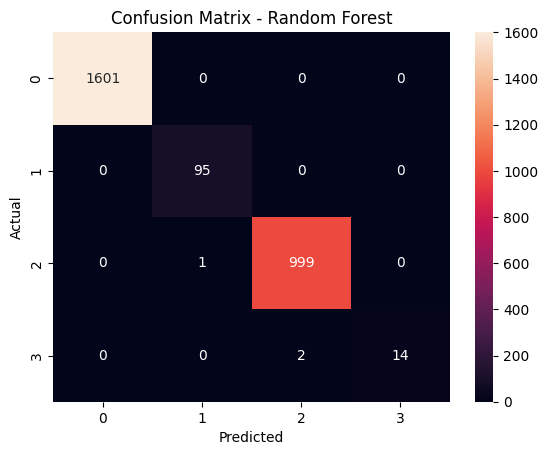


===== Logistic Regression =====
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1601
           1       0.81      0.73      0.77        95
           2       0.98      0.60      0.75      1000
           3       0.02      0.38      0.03        16

    accuracy                           0.84      2712
   macro avg       0.70      0.68      0.63      2712
weighted avg       0.97      0.84      0.88      2712



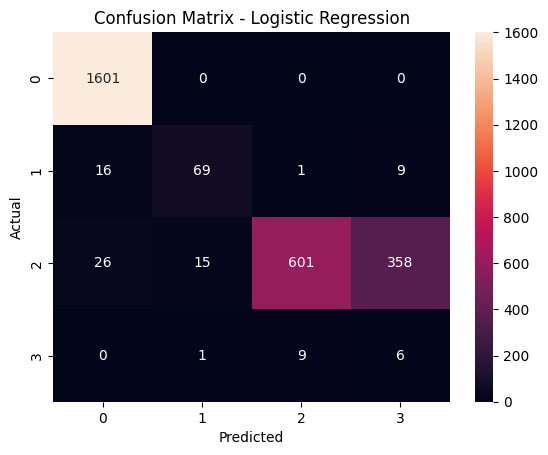

In [81]:
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    
    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred))
    
    cm = confusion_matrix(y_test, y_pred)
    
    plt.figure()
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

evaluate_model(rf, X_test, y_test, "Random Forest")
evaluate_model(lr, X_test_scaled, y_test, "Logistic Regression")

### 12. FEATURE IMPORTANCE (RF)


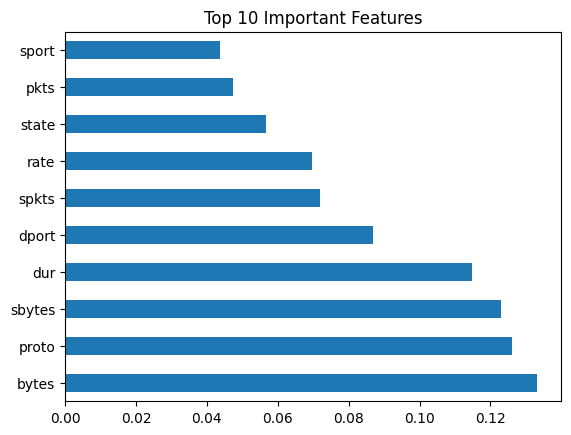

In [82]:
importances = rf.feature_importances_
feature_names = X.columns

feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

plt.figure()
feat_imp.head(10).plot(kind='barh')
plt.title("Top 10 Important Features")
plt.show()

In [83]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(rf, X, y, cv=5)
print(scores.mean())

0.9983771458789658


In [84]:
import pickle

# save Random Forest
with open("rf_model.pkl", "wb") as f:
    pickle.dump(rf, f)

# save Logistic Regression
with open("lr_model.pkl", "wb") as f:
    pickle.dump(lr, f)

# save scaler (rất quan trọng cho LR)
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("Models saved!")

Models saved!


# Class distribution

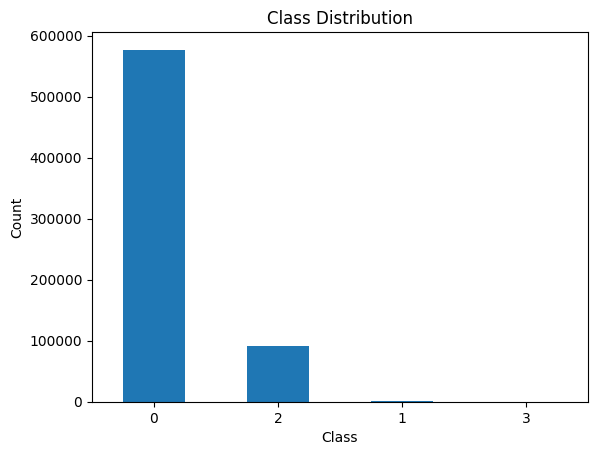

In [85]:
import matplotlib.pyplot as plt

plt.figure()
df['label'].value_counts().plot(kind='bar')
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

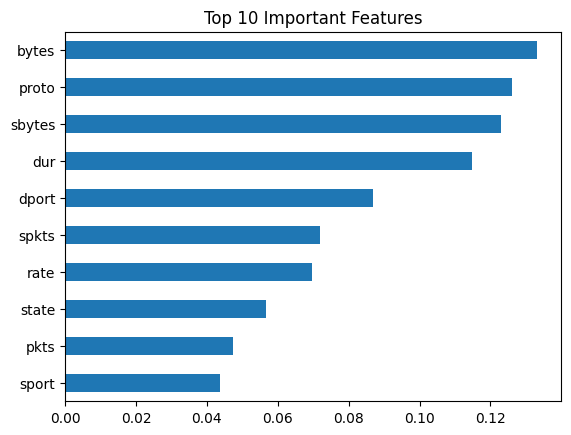

In [86]:
import pandas as pd

importances = rf.feature_importances_
feature_names = X.columns

feat_imp = pd.Series(importances, index=feature_names)
feat_imp = feat_imp.sort_values(ascending=False)

plt.figure()
feat_imp.head(10).plot(kind='barh')
plt.title("Top 10 Important Features")
plt.gca().invert_yaxis()
plt.show()

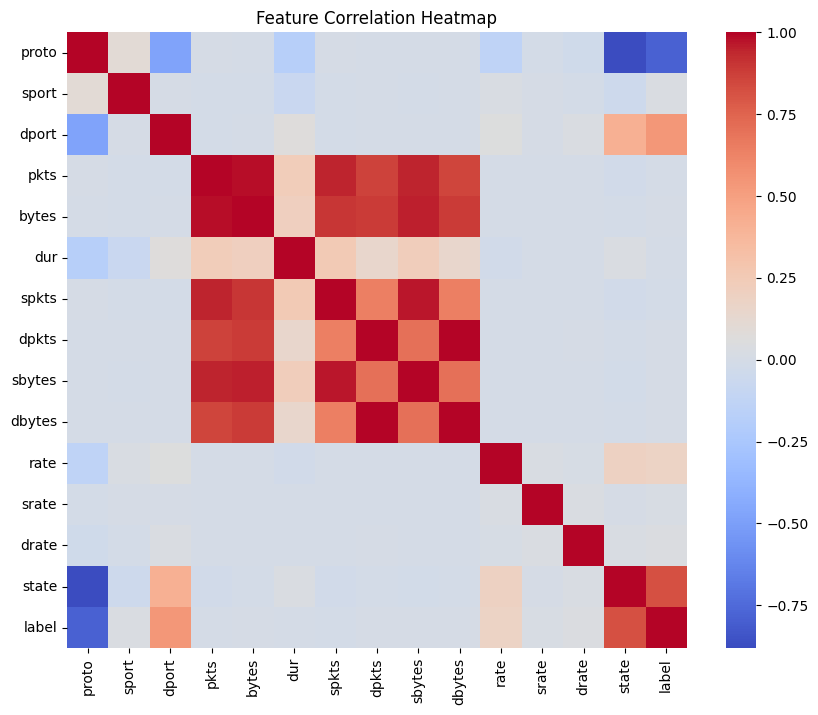

In [87]:
import seaborn as sns

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title("Feature Correlation Heatmap")
plt.show()

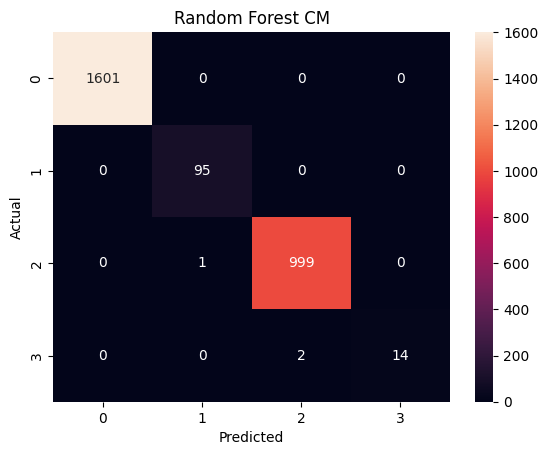

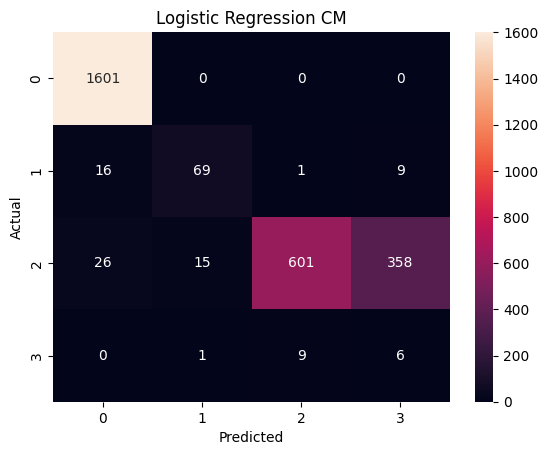

In [88]:
from sklearn.metrics import confusion_matrix

def plot_cm(model, X_test, y_test, title):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure()
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

plot_cm(rf, X_test, y_test, "Random Forest CM")
plot_cm(lr, X_test_scaled, y_test, "Logistic Regression CM")

                 Model  Accuracy  F1-score
0        Random Forest  0.998894  0.981650
1  Logistic Regression  0.839602  0.632672


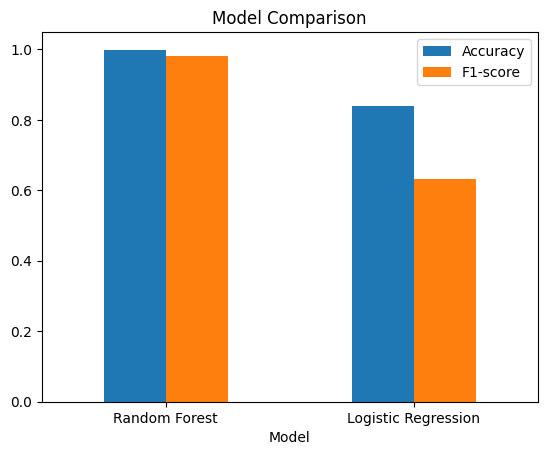

In [89]:
from sklearn.metrics import accuracy_score, f1_score

rf_pred = rf.predict(X_test)
lr_pred = lr.predict(X_test_scaled)

results = pd.DataFrame({
    "Model": ["Random Forest", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, lr_pred)
    ],
    "F1-score": [
        f1_score(y_test, rf_pred, average='macro'),
        f1_score(y_test, lr_pred, average='macro')
    ]
})

print(results)

# plot
results.set_index("Model").plot(kind='bar')
plt.title("Model Comparison")
plt.xticks(rotation=0)
plt.show()

In [90]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(rf, X, y, cv=5)

print("CV Mean:", scores.mean())
print("CV Scores:", scores)

CV Mean: 0.9983771458789658
CV Scores: [0.99778761 0.99815566 0.99926226 0.99926226 0.99741793]


In [93]:
import time

start = time.time()
rf.fit(X, y)
train_time = time.time() - start
print("Training time:", train_time)

Training time: 0.2528088092803955


In [95]:
start = time.time()
rf.predict(X_test)
pred_time = time.time() - start

print("Prediction time:", pred_time)
print("Time per sample:", pred_time / len(X_test))

Prediction time: 0.0513758659362793
Time per sample: 1.894390336883455e-05


In [97]:
import time

start = time.time()
lr.fit(X, y)
train_time = time.time() - start
print("Training time:", train_time)



Training time: 1.7196285724639893


f:\anaconda\envs\py310\lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [98]:
start = time.time()
lr.predict(X_test)
pred_time = time.time() - start

print("Prediction time:", pred_time)
print("Time per sample:", pred_time / len(X_test))

Prediction time: 0.0015568733215332031
Time per sample: 5.740683338986737e-07


In [101]:
import os

size1 = os.path.getsize("rf_model.pkl") / (1024*1024)
print("Random Forest Model size (MB):", size1)
size2 = os.path.getsize("lr_model.pkl") / (1024*1024)
print("Logistic Regression Model size (MB):", size2)

Random Forest Model size (MB): 1.2146329879760742
Logistic Regression Model size (MB): 0.0011606216430664062
